<div>
    <span style ="font-size: 32px; font-weight: bold; color: #8EB944">
        Imports
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import numpy as np
from itertools import product


In [2]:
from prophet import Prophet
from prophet.diagnostics import cross_validation, performance_metrics
from prophet.plot import plot_cross_validation_metric

In [3]:
from helper_functions import find_gaps, plot_forecast, plot_subseries, is_in_gap

In [ ]:
    '2018-01-01','2018-01-15', '2018-02-19','2018-03-31','2018-05-28','2018-07-04',
    '2018-09-03','2018-10-08','2018-11-12','2018-11-22','2018-11-23','2018-12-25',
    '2019-01-01','2019-01-21', '2019-02-18','2019-04-01','2019-05-27','2019-07-04',
    '2019-09-02','2019-11-11','2019-11-28','2019-11-29','2019-12-25',
    '2020-01-01','2020-01-20', '2020-02-17','2020-03-31','2020-05-25','2020-07-04',
    '2020-09-07','2020-11-11','2020-11-26','2020-11-27','2020-12-25',
    '2021-01-01','2021-01-18', '2021-02-15','2021-03-31','2021-05-31','2021-07-05',
    '2021-09-06','2021-11-11','2021-11-25','2021-11-26','2021-12-25',
    '2022-01-01','2022-01-17', '2022-02-21','2022-03-31','2022-05-30','2022-07-04',
    '2022-09-05','2022-11-11','2022-11-24','2022-11-25', '2022-12-26'


In [95]:
holidays_str = [
    '2018-01-01','2018-01-15', '2018-02-19','2018-03-31','2018-05-28','2018-07-04',
    '2018-09-03','2018-10-08','2018-11-12','2018-11-22','2018-11-23','2018-12-25',
    '2019-01-01','2019-01-21', '2019-02-18','2019-04-01','2019-05-27','2019-07-04',
    '2019-09-02','2019-11-11','2019-11-28','2019-11-29','2019-12-25',
    '2020-01-01','2020-01-20', '2020-02-17','2020-03-31','2020-05-25','2020-07-04',
    '2020-09-07','2020-11-11','2020-11-26','2020-11-27','2020-12-25',
    '2021-01-01','2021-01-18', '2021-02-15','2021-03-31','2021-05-31','2021-07-05',
    '2021-09-06','2021-11-11','2021-11-25','2021-11-26','2021-12-25',
    '2022-01-01','2022-01-17', '2022-02-21','2022-03-31','2022-05-30','2022-07-04',
    '2022-09-05','2022-11-11','2022-11-24','2022-11-25', '2022-12-26'
]



holidays = pd.DataFrame({
      'holiday': ['Holiday'] * len(holidays_str),  
    'ds': pd.to_datetime(holidays_str),
  'lower_window': 0,
  'upper_window': 0,
})




<div>
    <span style ="font-size: 32px; font-weight: bold; color: #8EB944">
        Hyperparameter Search
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

In [167]:
# === Step 1: Prepare data ===
data = pd.read_csv('utilization_filled.csv')
#data = data[data.site_01==0]

# make the binary features numeric
data['post_covid'] = (data['timestamp'] >= '2020-03-13').astype(int)
data['in_gap'] = data['in_gap'].astype(int)


# create a boolean version of the site variable --> required for custom seasonality
data['site_01_bool'] = data['site_01'].astype(bool)
# create a boolean variable for the site 2
data['site_02'] = (data['site_01'] == 0).astype(bool)

post_covid = data[data['timestamp'] >= '2018-10-08'].copy()
data_gaps = find_gaps(post_covid)
post_covid.rename(columns={'timestamp': 'ds', 'utilization_perc': 'y'}, inplace=True)


In [168]:

# === Step 2: Create a Train-Test split ===
train_data = post_covid[post_covid['ds'] < '2021-08-16']
test_data = post_covid[(post_covid['ds'] >= '2021-08-16') &(post_covid['ds']<= '2021-09-13 19:00')]

In [166]:



# Define parameter grid (using a smaller grid for demonstration)
param_grid = {
    'seasonality_prior_scale': [ 25,30, 50],
    'changepoint_range': [ 0.99, 0.95],
    'changepoint_prior_scale': [0.01, 0.05, 0.1],
    'holidays_prior_scale': [ 1, 5,10]
}

# Generate all combinations of parameters
all_params = [dict(zip(param_grid.keys(), v)) for v in product(*param_grid.values())]

# Storage for results
results = []



for params in all_params:
    try:
        model = Prophet(
            yearly_seasonality='auto',
            weekly_seasonality='auto',
            daily_seasonality=False,
            seasonality_mode="multiplicative",
            holidays_prior_scale=params['holidays_prior_scale'],
            changepoint_prior_scale=params['changepoint_prior_scale'],
            seasonality_prior_scale=params['seasonality_prior_scale'],
            changepoint_range=params['changepoint_range']
        )
        
        # Add conditional seasonalities and regressors
        
        model.add_seasonality(name='daily_site1', period=1, fourier_order=10, condition_name='site_01_bool')
        model.add_seasonality(name='daily_site2', period=1, fourier_order=10, condition_name='site_02')
        model.add_regressor('in_gap', mode='additive', prior_scale=0.05)
        model.add_regressor('site_01', mode='multiplicative', prior_scale=0.05)
        model.add_regressor('post_covid', mode='additive', prior_scale=0.05)
        
        # Fit model
        model.fit(train_data)
        
        # Cross validation
        cv_results = cross_validation(
            model,
            initial='500 days',
            period='90 days',
            horizon='30 days',
            parallel="processes"
        )
        
        # Performance metrics
        metrics = performance_metrics(cv_results)
        
        # Store results
        results.append({
            'params': params,
            'rmse': metrics['rmse'].mean(),
            'mae': metrics['mae'].mean(),
        })
       
        print(f"Completed parameters: {params}")
        print(f"RMSE: {metrics['rmse'].mean():.4f}, MAE: {metrics['mae'].mean():.4f}")
        print("-" * 50)
        
    except Exception as e:
        print(f"Error with parameters {params}: {str(e)}")
        continue

# Convert results to dataframe
results_df = pd.DataFrame(results)

# Find best parameters
best_params = results_df.loc[results_df['rmse'].idxmin(), 'params']
print("\
Best parameters:")
print(f"Seasonality Prior Scale: {best_params['seasonality_prior_scale']}")
print(f"Changepoint Range: {best_params['changepoint_range']}")
print(f"Changepoint Prior Scale: {best_params['changepoint_prior_scale']}")
print(f"Holidays Prior Scale: {best_params['holidays_prior_scale']}")
print("\
Best metrics:")
print(results_df.loc[results_df['rmse'].idxmin(), ['rmse', 'mae']])

18:09:49 - cmdstanpy - INFO - Chain [1] start processing
18:10:11 - cmdstanpy - INFO - Chain [1] done processing
18:10:20 - cmdstanpy - INFO - Chain [1] start processing
18:10:21 - cmdstanpy - INFO - Chain [1] start processing
18:10:22 - cmdstanpy - INFO - Chain [1] start processing
18:10:24 - cmdstanpy - INFO - Chain [1] start processing
18:10:25 - cmdstanpy - INFO - Chain [1] start processing
18:10:26 - cmdstanpy - INFO - Chain [1] done processing
18:10:26 - cmdstanpy - INFO - Chain [1] start processing
18:10:42 - cmdstanpy - INFO - Chain [1] done processing
18:10:53 - cmdstanpy - INFO - Chain [1] done processing
18:11:00 - cmdstanpy - INFO - Chain [1] done processing
18:11:03 - cmdstanpy - INFO - Chain [1] done processing
18:11:05 - cmdstanpy - INFO - Chain [1] done processing


Completed parameters: {'seasonality_prior_scale': 25, 'changepoint_range': 0.99, 'changepoint_prior_scale': 0.01, 'holidays_prior_scale': 1}
RMSE: 0.0796, MAE: 0.0553
--------------------------------------------------


18:11:14 - cmdstanpy - INFO - Chain [1] start processing
18:11:35 - cmdstanpy - INFO - Chain [1] done processing
18:11:44 - cmdstanpy - INFO - Chain [1] start processing
18:11:45 - cmdstanpy - INFO - Chain [1] start processing
18:11:46 - cmdstanpy - INFO - Chain [1] start processing
18:11:47 - cmdstanpy - INFO - Chain [1] start processing
18:11:49 - cmdstanpy - INFO - Chain [1] start processing
18:11:50 - cmdstanpy - INFO - Chain [1] start processing
18:11:50 - cmdstanpy - INFO - Chain [1] done processing
18:12:07 - cmdstanpy - INFO - Chain [1] done processing
18:12:19 - cmdstanpy - INFO - Chain [1] done processing
18:12:25 - cmdstanpy - INFO - Chain [1] done processing
18:12:29 - cmdstanpy - INFO - Chain [1] done processing
18:12:31 - cmdstanpy - INFO - Chain [1] done processing


Completed parameters: {'seasonality_prior_scale': 25, 'changepoint_range': 0.99, 'changepoint_prior_scale': 0.01, 'holidays_prior_scale': 5}
RMSE: 0.0796, MAE: 0.0553
--------------------------------------------------


18:12:41 - cmdstanpy - INFO - Chain [1] start processing
18:13:03 - cmdstanpy - INFO - Chain [1] done processing
18:13:12 - cmdstanpy - INFO - Chain [1] start processing
18:13:14 - cmdstanpy - INFO - Chain [1] start processing
18:13:15 - cmdstanpy - INFO - Chain [1] start processing
18:13:16 - cmdstanpy - INFO - Chain [1] start processing
18:13:17 - cmdstanpy - INFO - Chain [1] start processing
18:13:18 - cmdstanpy - INFO - Chain [1] done processing
18:13:18 - cmdstanpy - INFO - Chain [1] start processing
18:13:35 - cmdstanpy - INFO - Chain [1] done processing
18:13:47 - cmdstanpy - INFO - Chain [1] done processing
18:13:53 - cmdstanpy - INFO - Chain [1] done processing
18:13:57 - cmdstanpy - INFO - Chain [1] done processing
18:13:59 - cmdstanpy - INFO - Chain [1] done processing


Completed parameters: {'seasonality_prior_scale': 25, 'changepoint_range': 0.99, 'changepoint_prior_scale': 0.01, 'holidays_prior_scale': 10}
RMSE: 0.0796, MAE: 0.0553
--------------------------------------------------


... (98 outputs left out)

17:15:19 - cmdstanpy - INFO - Chain [1] start processing
17:16:05 - cmdstanpy - INFO - Chain [1] done processing
17:16:17 - cmdstanpy - INFO - Chain [1] start processing
17:16:18 - cmdstanpy - INFO - Chain [1] start processing
17:16:20 - cmdstanpy - INFO - Chain [1] start processing
17:16:21 - cmdstanpy - INFO - Chain [1] start processing
17:16:23 - cmdstanpy - INFO - Chain [1] start processing
17:16:24 - cmdstanpy - INFO - Chain [1] start processing
17:17:10 - cmdstanpy - INFO - Chain [1] done processing
17:17:26 - cmdstanpy - INFO - Chain [1] done processing
17:17:46 - cmdstanpy - INFO - Chain [1] done processing
17:17:49 - cmdstanpy - INFO - Chain [1] done processing
17:18:06 - cmdstanpy - INFO - Chain [1] done processing
17:18:11 - cmdstanpy - INFO - Chain [1] done processing


Completed parameters: {'seasonality_prior_scale': 50, 'changepoint_range': 0.95, 'changepoint_prior_scale': 0.1, 'holidays_prior_scale': 5}
RMSE: 0.0720, MAE: 0.0525
--------------------------------------------------


17:18:26 - cmdstanpy - INFO - Chain [1] start processing
17:19:08 - cmdstanpy - INFO - Chain [1] done processing
17:19:19 - cmdstanpy - INFO - Chain [1] start processing
17:19:20 - cmdstanpy - INFO - Chain [1] start processing
17:19:22 - cmdstanpy - INFO - Chain [1] start processing
17:19:23 - cmdstanpy - INFO - Chain [1] start processing
17:19:24 - cmdstanpy - INFO - Chain [1] start processing
17:19:25 - cmdstanpy - INFO - Chain [1] start processing
17:20:13 - cmdstanpy - INFO - Chain [1] done processing
17:20:30 - cmdstanpy - INFO - Chain [1] done processing
17:20:49 - cmdstanpy - INFO - Chain [1] done processing
17:20:52 - cmdstanpy - INFO - Chain [1] done processing
17:21:07 - cmdstanpy - INFO - Chain [1] done processing
17:21:10 - cmdstanpy - INFO - Chain [1] done processing


Completed parameters: {'seasonality_prior_scale': 50, 'changepoint_range': 0.95, 'changepoint_prior_scale': 0.1, 'holidays_prior_scale': 10}
RMSE: 0.0720, MAE: 0.0525
--------------------------------------------------
Best parameters:
Seasonality Prior Scale: 50
Changepoint Range: 0.95
Changepoint Prior Scale: 0.05
Holidays Prior Scale: 1
Best metrics:
rmse    0.067788
mae     0.047814
Name: 48, dtype: object


<div>
    <span style ="font-size: 32px; font-weight: bold; color: #8EB944">
        Fit and Forecast
    </span>
    
<hr style="color: #8EB944; height: 3px;background-color: #8EB944;border: none">
</div>

<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        1. Create a new instance of the cleaned dataframe
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [173]:
# === Step 1: Prepare data ===
data = pd.read_csv('utilization_filled.csv')
#data = data[data.site_01==0]

# make the binary features numeric
data['post_covid'] = (data['timestamp'] >= '2020-03-13').astype(int)
data['in_gap'] = data['in_gap'].astype(int)


# create a boolean version of the site variable --> required for custom seasonality
data['site_01_bool'] = data['site_01'].astype(bool)
# create a boolean variable for the site 2
data['site_02'] = (data['site_01'] == 0).astype(bool)

post_covid = data[data['timestamp'] >= '2018-10-08'].copy()
data_gaps = find_gaps(post_covid)
post_covid.rename(columns={'timestamp': 'ds', 'utilization_perc': 'y'}, inplace=True)


<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        2. Create a test-train-split
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [174]:
# let us use the last for 4 weeks of data for testing
train_data = post_covid[post_covid['ds'] < '2021-08-16']
test_data = post_covid[(post_covid['ds'] >= '2021-08-16') &(post_covid['ds']<= '2021-09-13 19:00')]

<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        3. Initialize the Prophet model
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [175]:
# let us use the hyperparameters determined in the cross-validation and hyperparameter search
model = Prophet(
    # 
    yearly_seasonality=False,

    # we add these 2 seasonalities with customized fourier orders
    weekly_seasonality=False,
    daily_seasonality=False,
    holidays=holidays,
    seasonality_mode="multiplicative",
    holidays_prior_scale=1,
    changepoint_prior_scale=0.05,
    seasonality_prior_scale=50,
    changepoint_range=0.95
   
)
# lets add custom seasonalities for site 1
# higher order fourier terms correspond to lower test errors.
model.add_seasonality(name='daily_site1', period=1, fourier_order=10, condition_name='site_01_bool')
model.add_seasonality(name='weekly_site1', period=7, fourier_order=9, condition_name='site_01_bool')
model.add_seasonality(name='yearly_site1', period=365.25, fourier_order=15, condition_name='site_01_bool')
# lets add custom seasonalities for site 2
model.add_seasonality(name='daily_site2', period=1, fourier_order=10, condition_name='site_02')
model.add_seasonality(name='weekly_site2', period=7, fourier_order=9, condition_name='site_02')
model.add_seasonality(name='yearly_site2', period=365.25, fourier_order=15, condition_name='site_02')


# add additive regressors
model.add_regressor('in_gap', mode='additive', prior_scale=0.05)
model.add_regressor('post_covid', mode='additive', prior_scale=0.05)

# add multiplicative regressors
model.add_regressor('site_01', mode='multiplicative', prior_scale=0.05)

<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        4. Fit the model on the training data
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [176]:
# fit the model
model.fit(train_data)



06:59:37 - cmdstanpy - INFO - Chain [1] start processing
07:00:28 - cmdstanpy - INFO - Chain [1] done processing


<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        5. Predict on the test data
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [177]:

# Create copies of test and train data to avoid errors
test_data = test_data.copy()  
train_data = train_data.copy()  

# ensure the ds column has the correct data type
test_data['ds'] = pd.to_datetime(test_data['ds'])
train_data['ds'] = pd.to_datetime(train_data['ds'])


# make the forecast
forecast_test = model.predict(test_data[['ds', 'in_gap', 'site_01','site_01_bool', 'site_02', 'post_covid']])
# merge forecast and original dataframe 
test_data = test_data.merge(forecast_test[['ds', 'yhat']], on='ds', how='left')

<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        6. Evaluate the model performance
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [178]:



train_forecast = model.predict(train_data[['ds', 'in_gap', 'site_01', 'site_01_bool', 'site_02', 'post_covid']])
train_data = train_data.merge(train_forecast[['ds', 'yhat']], on='ds', how='left')

# Compute Metrics


metrics = {
    'Dataset': ['Training', 'Test'],
    'MAE': [
        mean_absolute_error(train_data['y'], train_data['yhat']),
        mean_absolute_error(test_data['y'], test_data['yhat'])
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(train_data['y'], train_data['yhat'])),
        np.sqrt(mean_squared_error(test_data['y'], test_data['yhat']))
    ]
}

metrics_df = pd.DataFrame(metrics)
print(metrics_df)

    Dataset       MAE      RMSE
0  Training  0.084517  0.152946
1      Test  0.074433  0.129508


<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        7. Forecast 2 weeks into the future
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [179]:

future = model.make_future_dataframe(periods=42 * 24, freq='H')  # Forecast 28 days of hourly data
holiday_dates = [
    '2022-01-01', '2022-01-17', '2022-02-21', '2022-03-31', '2022-05-30',
    '2022-07-04', '2022-09-05', '2022-11-11', '2022-11-24', '2022-11-25', '2022-12-26',
]
future['holiday'] = future['ds'].dt.date.isin(holiday_dates).astype(int)
future['in_gap'] = future['ds'].apply(lambda x: is_in_gap(x, data_gaps))
future['site_01'] = 1
future['site_01_bool'] = future['site_01'].astype(bool)
future['site_02'] = 0
future['post_covid'] = future['ds'].apply(lambda x: x >= pd.Timestamp('2020-03-17')).astype(int)

forecast = model.predict(future)

<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        8. Visualize the forecast 
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

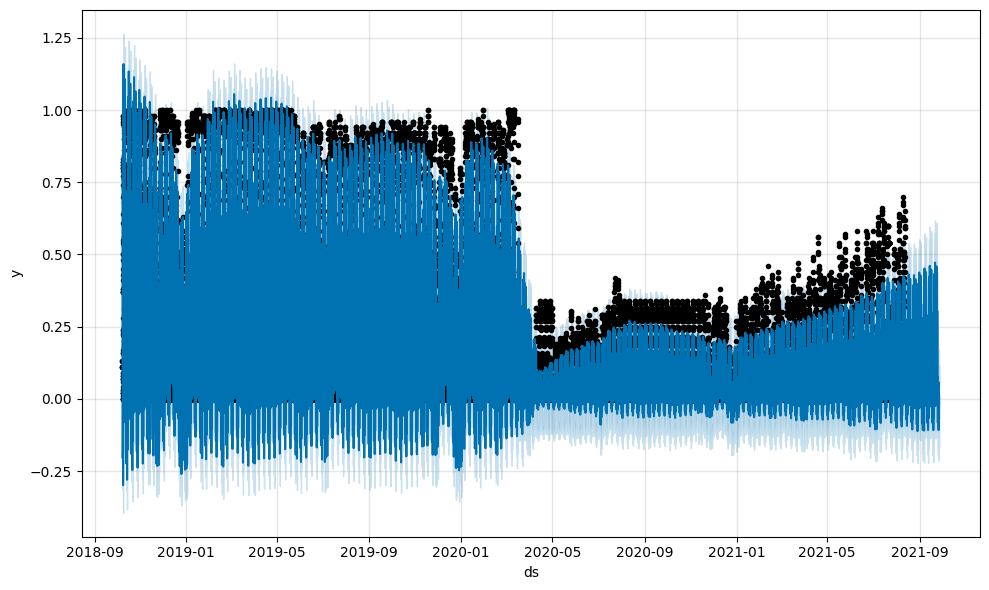

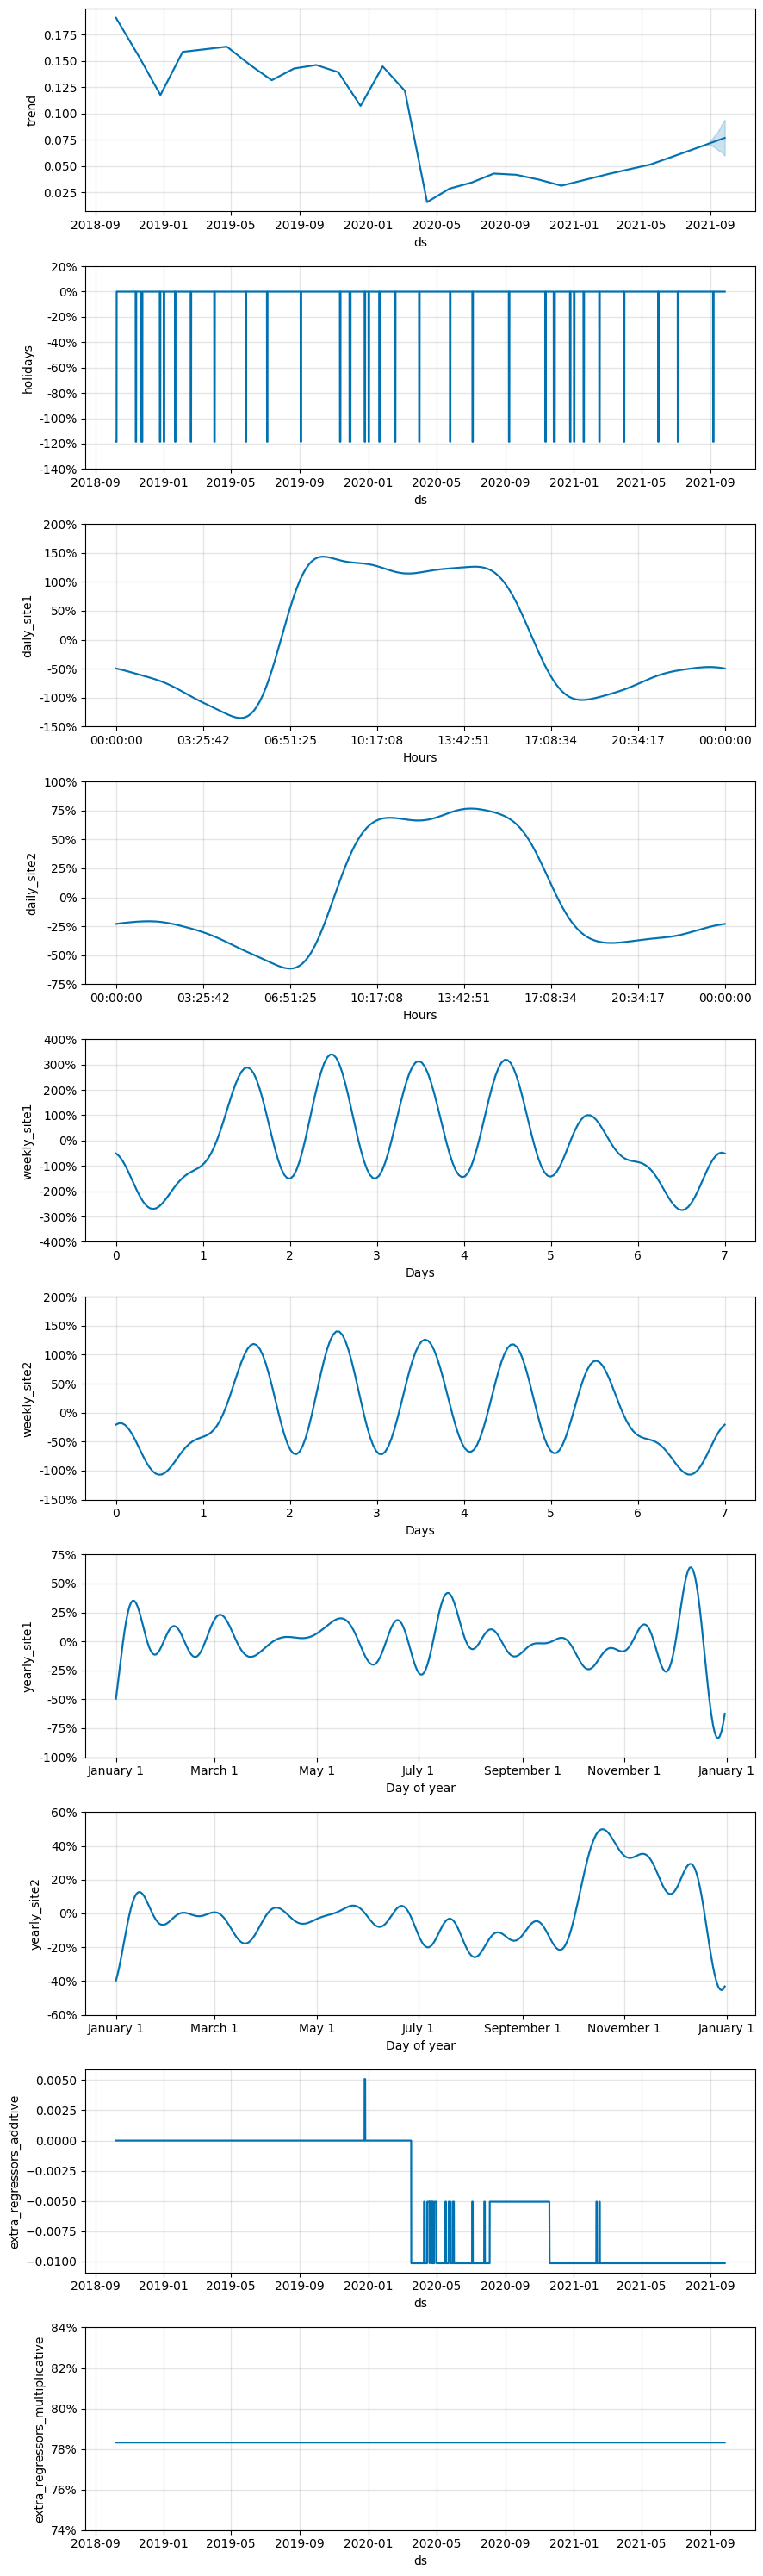

In [180]:
model.plot(forecast)
plt.show()

model.plot_components(forecast)
plt.show()

<span style ="font-size: 20px; font-weight: bold;color: #43556A;">
        9. Make a specific prediction
</span>
<hr style="color: #8EB944; height: 1px;background-color: #43556A;border: none">

In [181]:
specific_forecast = forecast.loc[forecast['ds'] == '2021-09-22 12:00']
print("Forecasted utilisation for 22.09.2021 12 AM:", specific_forecast['yhat'].values[0])

Forecasted utilisation for 22.09.2021 12 AM: 0.4523307352810858
